In [1]:
# ===== 노트북 설정: bandit.py 수정 시 자동 반영, src 폴더 경로 추가 =====
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT / "src"))
from bandit import FeatureBuilder, BernoulliTS, LinTS, ReplayData, run_repeated, summarize_results

# ===== 실험 설정 =====
CAMPAIGN = "men"
DATA_DIR = PROJECT_ROOT / "data"
SPLIT_TIME = pl.datetime(2019, 11, 26, time_zone="UTC")  # 조정 11/24~25 | 평가 11/26~30
SELECTED_SCALE = 0.1  # A(슬롯 미사용) 조정 결과

# ===== 데이터 로딩 및 정리 (EDA와 동일한 규칙: 인덱스 컬럼 삭제, 시간 변환, 중복 제거) =====
random_dir = DATA_DIR / "random" / CAMPAIGN
random_log_df = (
    pl.read_csv(random_dir / f"{CAMPAIGN}.csv")
    .drop("")
    .with_columns(pl.col("timestamp").str.to_datetime(format="%Y-%m-%d %H:%M:%S%.f%:z"))
    .unique(maintain_order=True)
)
item_df = pl.read_csv(random_dir / "item_context.csv").drop("")

# ===== 기간 분리 =====
tune_log_df = random_log_df.filter(pl.col("timestamp") < SPLIT_TIME)
eval_log_df = random_log_df.filter(pl.col("timestamp") >= SPLIT_TIME)

print(f"random 로그: {random_log_df.height:,}행 / 아이템: {item_df.height}개")
print(f"조정 기간: {tune_log_df.height:,}행 / 평가 기간: {eval_log_df.height:,}행")

random 로그: 452,868행 / 아이템: 34개
조정 기간: 134,902행 / 평가 기간: 317,966행


In [2]:
# ===== 피처 구성기: 기존(82차원, 비교용)과 슬롯 버전(169차원) =====
base_builder = FeatureBuilder().fit(random_log_df, item_df)
position_builder = FeatureBuilder(use_position=True).fit(random_log_df, item_df)
n_items = position_builder.n_items

# ===== 기간별 replay 데이터 (슬롯 버전) =====
tune_data_position = ReplayData(tune_log_df, position_builder)
eval_data_position = ReplayData(eval_log_df, position_builder)
print(f"[차원] 기존 {base_builder.n_dims} → 슬롯 버전 {position_builder.n_dims}")

# ===== 후보 행렬 확인: 앞 82차원은 기존과 동일, 슬롯 구간은 해당 슬롯 칸에만 값 =====
base_dims = base_builder.n_dims
item_dims = position_builder.n_item_dims
sample_row = 0
sample_user = tune_data_position.user_matrix[sample_row]
sample_flag = tune_data_position.interaction_flags[sample_row]
sample_position = int(tune_data_position.positions[sample_row])

sample_candidates = position_builder.build_candidates(sample_user, sample_flag, sample_position)
base_candidates = base_builder.build_candidates(sample_user, sample_flag)
position_onehot_part = sample_candidates[:, base_dims:base_dims + 3]
position_item_part = sample_candidates[:, base_dims + 3:]

print(f"\n[후보 행렬 확인] 샘플 행의 슬롯: {sample_position}")
print(f"shape: {sample_candidates.shape}")
print(f"앞 {base_dims}차원이 기존과 동일: {np.array_equal(sample_candidates[:, :base_dims], base_candidates)}")
print(f"슬롯 원-핫 (첫 행): {position_onehot_part[0]}")
for slot_number in range(1, 4):
    slot_part = position_item_part[:, (slot_number - 1) * item_dims:slot_number * item_dims]
    if np.array_equal(slot_part, position_builder.item_matrix):
        slot_status = "아이템 피처로 채워짐"
    elif np.all(slot_part == 0):
        slot_status = "전부 0"
    else:
        slot_status = "이상"
    print(f"슬롯{slot_number} × 아이템 칸: {slot_status}")

# ===== LinTS 소요 시간 측정 (조정 기간, 1회) =====
print("\n[슬롯 버전 LinTS 소요 시간 - 조정 기간, 1회]")
position_timing = run_repeated(
    lambda seed: LinTS(n_items, position_builder.n_dims, exploration_scale=SELECTED_SCALE, seed=seed),
    tune_data_position, n_runs=1,
)
seconds_per_row = position_timing[0].elapsed_seconds / tune_data_position.n_rows
print(f"행당 {seconds_per_row * 1e6:.0f}µs → 평가 기간 1회 예상 {seconds_per_row * eval_data_position.n_rows:.0f}초")

[차원] 기존 82 → 슬롯 버전 169

[후보 행렬 확인] 샘플 행의 슬롯: 1
shape: (34, 169)
앞 82차원이 기존과 동일: True
슬롯 원-핫 (첫 행): [1. 0. 0.]
슬롯1 × 아이템 칸: 아이템 피처로 채워짐
슬롯2 × 아이템 칸: 전부 0
슬롯3 × 아이템 칸: 전부 0

[슬롯 버전 LinTS 소요 시간 - 조정 기간, 1회]
  run  1/1: 일치 4,057 / 클릭 31 / CTR 0.7641% (15.6초)
행당 116µs → 평가 기간 1회 예상 37초


## LinTS 하이퍼파라미터 조정

## LinTS 평가기간 학습

[eval_lints_position] 50회 실행 중...
  완료 (2117초)

[평가 결과]
shape: (1, 5)
┌────────────┬──────────┬─────────────┬──────────────┬─────────────┐
│ policy     ┆ ctr_mean ┆ ctr_std_err ┆ matched_mean ┆ clicks_mean │
│ ---        ┆ ---      ┆ ---         ┆ ---          ┆ ---         │
│ str        ┆ f64      ┆ f64         ┆ f64          ┆ f64         │
╞════════════╪══════════╪═════════════╪══════════════╪═════════════╡
│ LinTS+slot ┆ 0.005102 ┆ 0.000103    ┆ 9307.3       ┆ 47.5        │
└────────────┴──────────┴─────────────┴──────────────┴─────────────┘
기준선 (평가 기간 실제 로그): Random 0.4828% / BTS 0.6454%

[LinTS+slot − LinTS(A)]
평균 -0.0022%p / 95% 신뢰구간 [-0.0313%p, +0.0269%p]


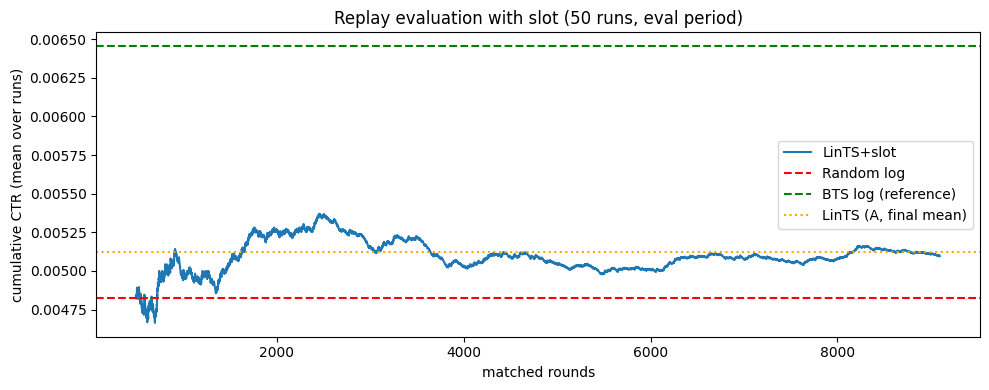

In [4]:
import pickle

# ===== 평가 설정 =====
N_EVAL_RUNS = 50
EVAL_BASE_SEED = 200  # A 평가와 동일 → 회차별 로그 순서 동일
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

eval_data_base = ReplayData(eval_log_df, base_builder)  # 슬롯 미사용 버전 (82차원)

# ===== 결과가 저장되어 있으면 불러오고, 없으면 실행 후 저장 =====
def run_or_load(result_name, policy_factory, replay_data):
    result_path = RESULTS_DIR / f"{CAMPAIGN}_{result_name}.pkl"
    if result_path.exists():
        print(f"[{result_name}] 저장된 결과 불러오기")
        with open(result_path, "rb") as result_file:
            return pickle.load(result_file)

    print(f"[{result_name}] {N_EVAL_RUNS}회 실행 중...")
    results = run_repeated(policy_factory, replay_data, n_runs=N_EVAL_RUNS,
                           base_seed=EVAL_BASE_SEED, verbose=False)
    print(f"  완료 ({sum(result.elapsed_seconds for result in results):.0f}초)")
    with open(result_path, "wb") as result_file:
        pickle.dump(results, result_file)
    return results

# ===== 세 정책 실행 =====
eval_results = {
    # "BernoulliTS": run_or_load(
    #     "eval_bernoulli_ts",
    #     lambda seed: BernoulliTS(n_items, seed=seed),
    #     eval_data_base,
    # ),
    # "LinTS": run_or_load(
    #     "eval_lints_base",
    #     lambda seed: LinTS(n_items, base_builder.n_dims, exploration_scale=SELECTED_SCALE, seed=seed),
    #     eval_data_base,
    # ),
    "LinTS+slot": run_or_load(
        "eval_lints_position",
        lambda seed: LinTS(n_items, position_builder.n_dims, exploration_scale=SELECTED_SCALE, seed=seed),
        eval_data_position,
    ),
}

# ===== 기준선: 평가 기간 실제 로그 CTR (Random, BTS) =====
DEDUP_KEY_COLS = ["timestamp", "item_id", "position", "click"]
bts_eval_ctr = (
    pl.scan_csv(DATA_DIR / "bts" / CAMPAIGN / f"{CAMPAIGN}.csv")
    .select(DEDUP_KEY_COLS)
    .unique()
    .with_columns(pl.col("timestamp").str.to_datetime(format="%Y-%m-%d %H:%M:%S%.f%:z"))
    .filter(pl.col("timestamp") >= SPLIT_TIME)
    .select(pl.col("click").mean())
    .collect()
    .item()
)
random_eval_ctr = eval_data_base.logged_ctr

# ===== 결과 요약표 =====
eval_summary_rows = []
for policy_name, results in eval_results.items():
    summary = summarize_results(results, policy_name)
    run_ctrs = np.array([result.ctr for result in results])
    summary["ctr_std_err"] = float(run_ctrs.std(ddof=1) / np.sqrt(len(run_ctrs)))
    eval_summary_rows.append(summary)

print("\n[평가 결과]")
print(pl.DataFrame(eval_summary_rows).select(
    "policy", "ctr_mean", "ctr_std_err", "matched_mean", "clicks_mean"
))
print(f"기준선 (평가 기간 실제 로그): Random {random_eval_ctr:.4%} / BTS {bts_eval_ctr:.4%}")

# # ===== 회차별 차이: 평균과 '평균 차이'의 95% 신뢰구간 (평균 ± 1.96 × 표준오차) =====
# print("\n[회차별 차이]")
# for better_name, worse_name in [("LinTS+slot", "LinTS"), ("LinTS", "BernoulliTS"), ("LinTS+slot", "BernoulliTS")]:
#     paired_diffs = np.array([
#         better_result.ctr - worse_result.ctr
#         for better_result, worse_result in zip(eval_results[better_name], eval_results[worse_name])
#     ])
#     diff_mean = paired_diffs.mean()
#     diff_std_err = paired_diffs.std(ddof=1) / np.sqrt(len(paired_diffs))
#     print(f"{better_name} − {worse_name}: 평균 {diff_mean:+.4%}p "
#           f"/ 95% 신뢰구간 [{diff_mean - 1.96 * diff_std_err:+.4%}p, {diff_mean + 1.96 * diff_std_err:+.4%}p] "
#           f"/ 앞쪽이 높았던 회차 {(paired_diffs > 0).mean():.0%}")

# ===== A의 기존 LinTS 결과와 평균 비교 (회차별 결과가 없어 평균·표준오차로 비교) =====
A_LINTS_CTR_MEAN = 0.005124
A_LINTS_STD_ERR = 0.000107

slot_ctrs = np.array([result.ctr for result in eval_results["LinTS+slot"]])
slot_ctr_mean = slot_ctrs.mean()
slot_std_err = slot_ctrs.std(ddof=1) / np.sqrt(len(slot_ctrs))

diff_mean = slot_ctr_mean - A_LINTS_CTR_MEAN
diff_std_err = np.sqrt(slot_std_err ** 2 + A_LINTS_STD_ERR ** 2)
print("\n[LinTS+slot − LinTS(A)]")
print(f"평균 {diff_mean:+.4%}p / 95% 신뢰구간 "
      f"[{diff_mean - 1.96 * diff_std_err:+.4%}p, {diff_mean + 1.96 * diff_std_err:+.4%}p]")

# ===== 평균 누적 클릭률 추이 =====
BURN_IN = 500
fig, axis = plt.subplots(figsize=(10, 4))
for policy_name, results in eval_results.items():
    common_length = min(result.n_matched for result in results)
    mean_curve = np.mean([result.cumulative_ctr[:common_length] for result in results], axis=0)
    axis.plot(np.arange(BURN_IN, common_length), mean_curve[BURN_IN:], label=policy_name)
axis.axhline(random_eval_ctr, color="red", linestyle="--", label="Random log")
axis.axhline(bts_eval_ctr, color="green", linestyle="--", label="BTS log (reference)")
axis.axhline(A_LINTS_CTR_MEAN, color="orange", linestyle=":", label="LinTS (A, final mean)")
axis.set_xlabel("matched rounds")
axis.set_ylabel("cumulative CTR (mean over runs)")
axis.set_title(f"Replay evaluation with slot ({N_EVAL_RUNS} runs, eval period)")
axis.legend()
plt.tight_layout()
plt.show()